# 03 - Xử lý mất cân bằng lớp: `class_weight` vs SMOTE

Mục tiêu: so sánh `class_weight="balanced"` với SMOTE trên **cùng một mô hình, cùng 5 fold**, và ghi nhận ảnh hưởng đến **Recall lớp Dropout** (và Macro-F1, F1 lớp Enrolled).

Quy tắc: SMOTE đặt **trong Pipeline** nên chỉ áp trên phần train của từng fold, validation giữ nguyên phân phối thật. Tập test không được dùng.

In [1]:
import os, sys, warnings
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from src import config
from src.data import get_train_test
from src.evaluate import cross_validate_model
from src.imbalance import build_smote_pipeline, HAS_IMBLEARN
from src.preprocessing import build_pipeline

sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
X_train, X_test, y_train, y_test = get_train_test("C")   # tập test KHÔNG dùng trong notebook này
print(X_train.shape, "| imblearn có sẵn:", HAS_IMBLEARN)
print(y_train.value_counts(normalize=True).round(3).to_dict())

(3539, 36) | imblearn có sẵn: False
{'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.179}


## 1. Mức độ mất cân bằng

Graduate ~50%, Dropout ~32%, Enrolled ~18% (tỷ lệ lớp lớn nhất / nhỏ nhất ≈ 2,8). Mất cân bằng ở mức vừa; mô hình không xử lý có xu hướng ưu tiên Graduate và bỏ sót Enrolled.

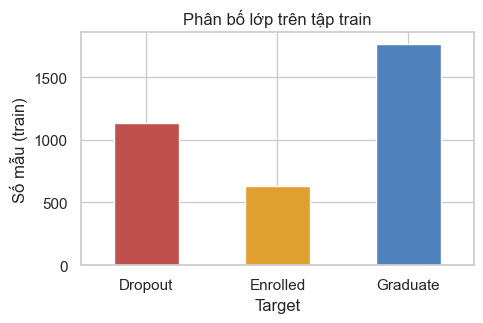

In [2]:
ax = y_train.value_counts().reindex(config.CLASSES).plot(kind="bar", color=["#c0504d", "#e0a030", "#4f81bd"], figsize=(5, 3.4))
ax.set_ylabel("Số mẫu (train)"); ax.set_title("Phân bố lớp trên tập train"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "03_imbalance_class_dist.png", dpi=200); plt.show()

## 2. Ba chiến lược trên cùng một mô hình

- **none**: không xử lý
- **class_weight**: `class_weight="balanced"` (phạt lỗi lớp ít mẫu nặng hơn)
- **SMOTE**: sinh mẫu tổng hợp cho Dropout/Enrolled bằng nội suy láng giềng, chỉ trên fold train

Hai mô hình: Logistic Regression (có chuẩn hóa) và Random Forest (không cần chuẩn hóa). Cùng `Stratified 5-fold`, `random_state=42`.

In [3]:
def make(model, strategy, fs="C"):
    scale = model == "LogisticRegression"
    if model == "LogisticRegression":
        mk = lambda cw: LogisticRegression(max_iter=3000, class_weight=cw)
    else:
        mk = lambda cw: RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight=cw,
                                               random_state=config.RANDOM_STATE, n_jobs=-1)
    if strategy == "none":
        return build_pipeline(mk(None), fs, scale)
    if strategy == "class_weight":
        return build_pipeline(mk("balanced"), fs, scale)
    return build_smote_pipeline(mk(None), fs, scale)

rows = []
for model in ["LogisticRegression", "RandomForest"]:
    for strategy in ["none", "class_weight", "SMOTE"]:
        r = cross_validate_model(make(model, strategy), X_train, y_train, name=f"{model}+{strategy}",
                                 feature_set="C", log=False, n_jobs=1)
        rows.append({"model": model, "strategy": strategy,
                     "f1_macro": r["f1_macro_mean"], "f1_macro_std": r["f1_macro_std"],
                     "recall_dropout": r["recall_dropout_mean"], "recall_dropout_std": r["recall_dropout_std"],
                     "f1_enrolled": r["f1_enrolled_mean"], "balanced_acc": r["balanced_accuracy_mean"],
                     "accuracy": r["accuracy_mean"], "train_f1_macro": r["train_f1_macro_mean"]})
res = pd.DataFrame(rows).round(4)
res.to_csv(config.RESULTS_DIR / "imbalance_comparison.csv", index=False)
res

,model,strategy,f1_macro,f1_macro_std,recall_dropout,recall_dropout_std,f1_enrolled,balanced_acc,accuracy,train_f1_macro
0,LogisticRegression,none,0.6983,0.0178,0.7748,0.0218,0.4524,0.6891,0.7739,0.7451
1,LogisticRegression,class_weight,0.7114,0.0138,0.7361,0.0252,0.5232,0.7199,0.7519,0.7575
2,LogisticRegression,SMOTE,0.7013,0.0149,0.7414,0.0260,0.5003,0.7080,0.7457,0.7571
3,RandomForest,none,0.6785,0.0220,0.7739,0.0227,0.3927,0.6709,0.7700,0.8919
4,RandomForest,class_weight,0.7165,0.0194,0.7440,0.0233,0.5117,0.7136,0.7703,0.9212
5,RandomForest,SMOTE,0.7125,0.0173,0.7564,0.0151,0.4901,0.7064,0.7734,0.9298


## 3. Hình so sánh

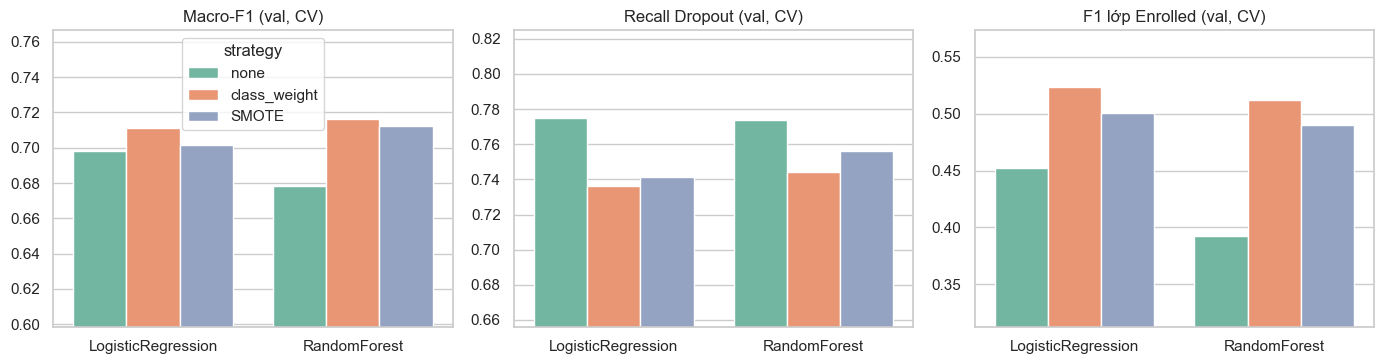

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, title) in zip(axes, [("f1_macro", "Macro-F1 (val, CV)"), ("recall_dropout", "Recall Dropout (val, CV)"),
                                   ("f1_enrolled", "F1 lớp Enrolled (val, CV)")]):
    sns.barplot(data=res, x="model", y=col, hue="strategy", ax=ax, palette="Set2")
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_ylim(max(0, res[col].min() - 0.08), min(1, res[col].max() + 0.05))
    if ax is not axes[0]: ax.get_legend().remove()
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "03_imbalance_comparison.png", dpi=200); plt.show()

## 4. Chênh lệch so với không xử lý

In [5]:
base = res[res.strategy == "none"].set_index("model")
diff = res[res.strategy != "none"].copy()
for c in ["f1_macro", "recall_dropout", "f1_enrolled"]:
    diff[f"d_{c}"] = diff.apply(lambda r: r[c] - base.loc[r["model"], c], axis=1)
diff[["model", "strategy", "d_f1_macro", "d_recall_dropout", "d_f1_enrolled"]].round(4)

,model,strategy,d_f1_macro,d_recall_dropout,d_f1_enrolled
1,LogisticRegression,class_weight,0.0131,-0.0387,0.0708
2,LogisticRegression,SMOTE,0.0030,-0.0334,0.0479
4,RandomForest,class_weight,0.0380,-0.0299,0.1190
5,RandomForest,SMOTE,0.0340,-0.0175,0.0974


## 5. Nhận xét

In [6]:
for m in res.model.unique():
    d = res[res.model == m].set_index("strategy")
    best = d.f1_macro.idxmax()
    print(f"{m}: Macro-F1 cao nhất = {best} ({d.f1_macro[best]:.4f}); "
          f"Recall Dropout none/class_weight/SMOTE = "
          f"{d.recall_dropout['none']:.3f}/{d.recall_dropout['class_weight']:.3f}/{d.recall_dropout['SMOTE']:.3f}; "
          f"F1 Enrolled = {d.f1_enrolled['none']:.3f}/{d.f1_enrolled['class_weight']:.3f}/{d.f1_enrolled['SMOTE']:.3f}")

LogisticRegression: Macro-F1 cao nhất = class_weight (0.7114); Recall Dropout none/class_weight/SMOTE = 0.775/0.736/0.741; F1 Enrolled = 0.452/0.523/0.500
RandomForest: Macro-F1 cao nhất = class_weight (0.7165); Recall Dropout none/class_weight/SMOTE = 0.774/0.744/0.756; F1 Enrolled = 0.393/0.512/0.490


- **Macro-F1**: `class_weight="balanced"` cho kết quả tốt nhất ở cả hai mô hình (LR 0,698 → 0,711; RF 0,679 → 0,725). SMOTE cũng cải thiện nhưng ít hơn (LR 0,701; RF 0,713).
- **F1 lớp Enrolled** tăng rõ nhất (LR 0,452 → 0,523 với class_weight; RF 0,393 → 0,539). Đây là lớp thiểu số khó nhất nên cân bằng giúp nhiều nhất ở đây.
- **Recall Dropout không tăng mà giảm nhẹ** (LR 0,775 → 0,736 / 0,741; RF 0,774 → 0,738 / 0,757). Lý do: khi tăng trọng số cho Enrolled, mô hình chuyển một phần mẫu Dropout sang dự đoán Enrolled. Vì vậy cân bằng lớp không thay thế được việc chỉnh ngưỡng Dropout (issue #14).
- Độ lệch chuẩn giữa các fold khoảng 0,014 - 0,022, nên chênh lệch SMOTE vs class_weight của LR (0,010) nằm trong nhiễu; chênh lệch của RF (0,012) cũng sát mức nhiễu, chỉ có thể nói class_weight không kém SMOTE.
- Kết luận cho nhóm: dùng `class_weight="balanced"` làm mặc định (đơn giản, không cần sinh mẫu, không làm tăng thời gian chạy). Dùng cho LR, RF, SVM; Gradient Boosting của sklearn không có tham số này.
